# Job Category Classifier

Predicts which of six job-board categories a job ad belongs to.

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd

df = pd.read_parquet('data/raw/djinni-jobs-en.parquet')
df.shape

(141897, 10)

## 2. First look

In [2]:
df.head().T

,0,1,2,3,4
Position,10 + Blockchain Nodes / Masternodes to set up,10 .NET Developers (Middle and Senior level),"10X Engineer (co-founder, #4 employee, USD 11-...",16 - Amazon Brand Manager,16 - Amazon Brand Manager
Long Description,*Requirements*\r\n\r\nWe're looking for a long...,"Greetings! My name is Maria, I am in urgent ne...",**Product**\r\nThe product is a live video cha...,"Currently, TCM expanding its activities to Ukr...","Hello,\r\nWe, MIMIRB2B, are an outstaff compan..."
Company Name,MyCointainer,TechScout.tech,Innoteka,FirstFive,MimirB2B
Exp Years,2y,2y,5y,2y,1y
Primary Keyword,Sysadmin,.NET,JavaScript,Marketing,Marketing
English Level,intermediate,intermediate,fluent,upper,upper
Published,2020-10-01T00:00:00+03:00,2022-03-01T00:00:00+02:00,2021-07-01T00:00:00+03:00,2022-01-01T00:00:00+02:00,2021-12-01T00:00:00+02:00
Long Description_lang,en,en,en,en,en
id,c0ca96e7-85df-50df-a64e-d934cd02a170,64f4b7ea-36e4-5bdd-a8b1-185f32f7dc7f,b9a1303e-dd0c-5ed1-8f62-be2bc4c7da4f,99cb3f4a-9b4b-53d9-9a3b-bab2c22da346,bc1419f7-28e2-582b-8d53-22e28b2f0210
__index_level_0__,27461,27462,27463,27464,27465


In [3]:
df.dtypes

Position                   str
Long Description           str
Company Name               str
Exp Years                  str
Primary Keyword            str
English Level              str
Published                  str
Long Description_lang      str
id                         str
__index_level_0__        int64
dtype: object

Column names in lower case with `_`, as in the course.

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
df.columns

Index(['position', 'long_description', 'company_name', 'exp_years',
       'primary_keyword', 'english_level', 'published',
       'long_description_lang', 'id', '__index_level_0__'],
      dtype='str')

## 3. Missing values

Missing `english_level` becomes `'NA'`, then we check for empty strings.

In [5]:
df.isnull().sum()

position                    0
long_description            0
company_name                0
exp_years                   0
primary_keyword             0
english_level            7539
published                   0
long_description_lang       0
id                          0
__index_level_0__           0
dtype: int64

In [6]:
df.english_level = df.english_level.fillna('NA')
df.english_level.value_counts()

english_level
upper           66948
intermediate    54965
fluent          10583
NA               7539
pre              1689
basic             173
Name: count, dtype: int64

In [7]:
string_columns = list(df.dtypes[df.dtypes == 'str'].index)

In [8]:
for c in string_columns:
    s = df[c].str.strip()
    print(c, 'empty:', (s == '').sum(), 'shortest:', s.str.len().min())

position empty: 0 shortest: 2
long_description empty: 0 shortest: 51
company_name empty: 0 shortest: 2
exp_years empty: 0 shortest: 2
primary_keyword empty: 0 shortest: 2
english_level empty: 0 shortest: 2
published empty: 0 shortest: 25
long_description_lang empty: 0 shortest: 2
id empty: 0 shortest: 36


## 4. Publication date

Only the date part is kept, because converting to UTC moves each ad to the previous month.

In [9]:
pd.to_datetime(df.published.head(3), utc=True)

0   2020-09-30 21:00:00+00:00
1   2022-02-28 22:00:00+00:00
2   2021-06-30 21:00:00+00:00
Name: published, dtype: datetime64[us, UTC]

In [10]:
df.published = pd.to_datetime(df.published.str[:10])
df.published.min(), df.published.max(), df.published.nunique()

(Timestamp('2020-01-01 00:00:00'), Timestamp('2023-09-01 00:00:00'), 45)

## 5. Duplicates

The same ad in training and test data would make the model look better than it is.

In [11]:
df.id.duplicated().sum(), df.drop(columns='__index_level_0__').duplicated().sum()

(np.int64(0), np.int64(0))

In [12]:
description_norm = df.long_description.str.lower().str.split().str.join(' ')
description_norm.duplicated().sum()

np.int64(0)

In [13]:
df['description_start'] = description_norm.str[:300]
df['company_norm'] = df.company_name.str.lower().str.strip()

In [14]:
companies_per_start = df.groupby('description_start').company_norm.nunique()
shared = companies_per_start[companies_per_start > 1]
len(shared), df.description_start.isin(shared.index).sum()

(329, np.int64(1010))

Mostly the same company under different names, or an agency posting other companies' ads.

In [15]:
examples = df[df.description_start.isin(shared.index)].sort_values('description_start')
examples[['company_norm', 'position', 'primary_keyword', 'description_start']].head(15)

,company_norm,position,primary_keyword,description_start
3337,scalors,Android Software Developer,Android,**about client:** kivu technologies is an inno...
32590,scalors gmbh,Front-End Developer for Kivu,JavaScript,**about client:** kivu technologies is an inno...
59927,intellectsoft,Lead Full-Stack .NET,.NET,**about intellectsoft:** we are a digital tran...
62100,intellectsoft,Lead/Senior Java developer,Java,**about intellectsoft:** we are a digital tran...
124654,intellectsoft,Senior React Developer,JavaScript,**about intellectsoft:** we are a digital tran...
66605,intlectsoft,Middle Android Developer,Android,**about intellectsoft:** we are a digital tran...
62033,clario,Lead/Senior Affiliate Marketing Manager,Marketing,"**about our products** our product, with its i..."
134352,сlario,Talent Acquisition Specialist,HR,"**about our products** our product, with its i..."
40858,clario,Golang Developer (Mid or Senior),Golang,"**about our products** our product, with its i..."
109290,clario,Senior Data Engineer,Data Engineer,"**about our products** our product, with its i..."


## 6. Company groups

Companies whose ads start with the same 300 characters form one group.

In [16]:
df['company_group'] = df.company_norm

while True:
    before = df.company_group.copy()
    df['company_group'] = df.groupby('description_start').company_group.transform('min')
    df['company_group'] = df.groupby('company_norm').company_group.transform('min')
    if (df.company_group == before).all():
        break

df.company_norm.nunique(), df.company_group.nunique()

(10197, 9924)

In [17]:
df.company_group.value_counts().head(10)

company_group
at it-rex - staffing services    9046
adaptiq                          3445
101ants                          3306
epam                             2032
a-hr                             1721
daxx                             1447
8allocate                        1443
benefit agency                   1231
chi                              1204
artkai                           1087
Name: count, dtype: int64

## 7. The six categories

The classes are imbalanced, so macro F1 is the main metric.

In [18]:
categories = ['JavaScript', 'Java', 'DevOps', 'QA Automation', 'Python', 'Data Science']
df = df[df.primary_keyword.isin(categories)].reset_index(drop=True)
df.shape

(49638, 13)

In [19]:
df.primary_keyword.value_counts()

primary_keyword
JavaScript       17903
Java              8712
DevOps            7979
QA Automation     7047
Python            5735
Data Science      2262
Name: count, dtype: int64

In [20]:
df.primary_keyword.value_counts(normalize=True).round(3)

primary_keyword
JavaScript       0.361
Java             0.176
DevOps           0.161
QA Automation    0.142
Python           0.116
Data Science     0.046
Name: proportion, dtype: float64

## 8. Text for the model

Title and text together, with whitespace collapsed and punctuation kept.

In [21]:
df['text'] = (df.position + ' ' + df.long_description).str.split().str.join(' ')
df.text.iloc[0][:300]

'10X Engineer (co-founder, #4 employee, USD 11-12k, 1-4% equity) **Product** The product is a live video chat and co-browsing with website visitors. It helps companies generate more customers with instant video meetings directly on visitor’s website while they’re browsing a company’s page. It’s like '

In [22]:
df.text.str.len().describe()

count    49638.000000
mean      1745.891394
std        949.370331
min         77.000000
25%       1066.000000
50%       1576.000000
75%       2227.000000
max      12400.000000
Name: text, dtype: float64

## 9. Train, validation and test split

Groups are split 60/20/20 with `random_state=1`, which gives 69/16/15 of the ads because some groups are large.

In [23]:
from sklearn.model_selection import train_test_split

groups = df.company_group.drop_duplicates()
groups_full_train, groups_test = train_test_split(groups, test_size=0.2, random_state=1)
groups_train, groups_val = train_test_split(groups_full_train, test_size=0.25, random_state=1)

df_train = df[df.company_group.isin(groups_train)].reset_index(drop=True)
df_val = df[df.company_group.isin(groups_val)].reset_index(drop=True)
df_test = df[df.company_group.isin(groups_test)].reset_index(drop=True)

len(df_train), len(df_val), len(df_test)

(34039, 8021, 7578)

In [24]:
(set(df_train.company_group) & set(df_val.company_group),
 set(df_train.company_group) & set(df_test.company_group),
 set(df_val.company_group) & set(df_test.company_group))

(set(), set(), set())

In [25]:
pd.DataFrame({
    'train': df_train.primary_keyword.value_counts(normalize=True),
    'val': df_val.primary_keyword.value_counts(normalize=True),
    'test': df_test.primary_keyword.value_counts(normalize=True),
}).round(3)

,train,val,test
primary_keyword,,,
Data Science,0.045,0.050,0.044
DevOps,0.164,0.146,0.160
Java,0.184,0.159,0.153
JavaScript,0.345,0.385,0.404
Python,0.111,0.134,0.117
QA Automation,0.150,0.126,0.122


# Exploratory data analysis

Only the training set is used from here on.

## 10. Ad length by category

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

df_train['text_len'] = df_train.text.str.len()
df_train.groupby('primary_keyword').text_len.describe().round(0)

,count,mean,std,min,25%,50%,75%,max
primary_keyword,,,,,,,,
Data Science,1529.0,2002.0,1092.0,271.0,1250.0,1795.0,2516.0,8294.0
DevOps,5597.0,1956.0,1030.0,128.0,1218.0,1776.0,2467.0,8554.0
Java,6276.0,1805.0,981.0,160.0,1115.0,1647.0,2269.0,9012.0
JavaScript,11753.0,1619.0,869.0,77.0,984.0,1463.0,2056.0,8944.0
Python,3778.0,1685.0,964.0,169.0,1002.0,1484.0,2168.0,12400.0
QA Automation,5106.0,1877.0,961.0,239.0,1167.0,1709.0,2418.0,6550.0


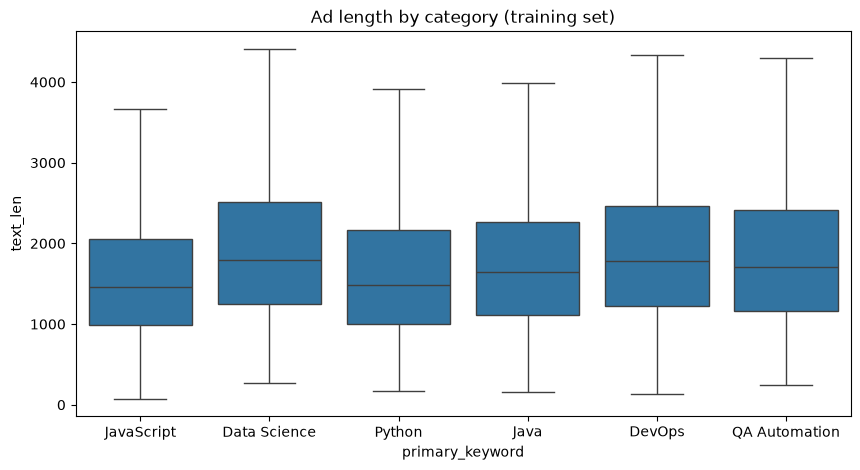

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_train, x='primary_keyword', y='text_len', showfliers=False)
plt.title('Ad length by category (training set)')
plt.show()

Lengths overlap almost completely, so length is not used as a feature.

## 11. English level and experience

Share of Data Science ads per group, as in the course's churn analysis.

In [28]:
df_train['data_science'] = (df_train.primary_keyword == 'Data Science').astype(int)
global_rate = df_train.data_science.mean()

for c in ['english_level', 'exp_years']:
    df_group = df_train.groupby(c).data_science.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_rate
    df_group['risk'] = df_group['mean'] / global_rate
    display(df_group.round(3))

,mean,count,diff,risk
english_level,,,,
NA,0.039,1737,-0.006,0.872
basic,0.000,36,-0.045,0.000
fluent,0.077,918,0.032,1.722
intermediate,0.037,15598,-0.008,0.825
pre,0.025,321,-0.020,0.555
upper,0.052,15429,0.007,1.160


,mean,count,diff,risk
exp_years,,,,
1y,0.052,3085,0.007,1.155
2y,0.047,8107,0.002,1.035
3y,0.042,14218,-0.003,0.935
5y,0.044,7759,-0.001,0.973
no_exp,0.064,870,0.019,1.433


In [29]:
df_train.groupby('english_level').primary_keyword.value_counts(normalize=True).unstack().fillna(0).round(3)

primary_keyword,Data Science,DevOps,Java,JavaScript,Python,QA Automation
english_level,,,,,,
NA,0.039,0.180,0.154,0.399,0.116,0.112
basic,0.000,0.028,0.083,0.667,0.194,0.028
fluent,0.077,0.172,0.200,0.318,0.124,0.108
intermediate,0.037,0.159,0.178,0.358,0.105,0.162
pre,0.025,0.162,0.112,0.511,0.109,0.081
upper,0.052,0.168,0.195,0.324,0.115,0.146


In [30]:
from sklearn.metrics import mutual_info_score

for c in ['english_level', 'exp_years']:
    print(c, round(mutual_info_score(df_train[c], df_train.primary_keyword), 4))

english_level 0.0039
exp_years 0.01


Both columns carry very little information about the category, so the first model uses only the text.

## 12. Characteristic words

Words are counted once per ad and ranked by how much more often they appear in a category than overall.

In [31]:
import re

def tokenize(text):
    words = re.findall(r'[a-z0-9+#.]+', text.lower())
    return [w.rstrip('.') for w in words if w.rstrip('.')]

tokenize('Senior C++/C# .NET Developer, Node.js and Python. 5+ years')

['senior',
 'c++',
 'c#',
 '.net',
 'developer',
 'node.js',
 'and',
 'python',
 '5+',
 'years']

In [32]:
df_train['words'] = df_train.text.apply(lambda t: set(tokenize(t)))
df_words = df_train[['primary_keyword', 'words']].explode('words')

category_size = df_train.primary_keyword.value_counts()
share = df_words.groupby('primary_keyword').words.value_counts().div(category_size, level='primary_keyword')
share['JavaScript'].head(10)

words
and           0.983749
of            0.971412
with          0.966562
in            0.932102
experience    0.931081
to            0.929635
the           0.919765
a             0.916107
for           0.833915
developer     0.798009
Name: count, dtype: float64

In [33]:
overall = df_words.words.value_counts() / len(df_train)

df_share = share.rename('share').reset_index()
df_share['overall'] = df_share.words.map(overall)
df_share['risk'] = df_share.share / df_share.overall

top = (df_share[df_share.share >= 0.05]
       .sort_values('risk', ascending=False)
       .groupby('primary_keyword').head(8))
top

,primary_keyword,words,share,overall,risk
74,Data Science,scientist,0.332897,0.016628,20.020304
162,Data Science,statistical,0.204055,0.012456,16.381665
524,Data Science,probability,0.074559,0.004789,15.569926
672,Data Science,phd,0.056900,0.003760,15.131382
297,Data Science,tableau,0.129496,0.008755,14.791705
493,Data Science,keras,0.077829,0.005288,14.717829
403,Data Science,scikit,0.096795,0.006639,14.578827
486,Data Science,classification,0.079137,0.005641,14.029864
78366,Python,celery,0.082319,0.009842,8.364316
78507,Python,sqlalchemy,0.059291,0.007374,8.040613


## 13. Noise in the categories

The job board's categories overlap, for example Data Science ads for data engineers.

In [34]:
ds = df_train[df_train.primary_keyword == 'Data Science']
ds.position.str.lower().str.contains('data engineer').mean()

np.float64(0.2223675604970569)

In [35]:
ds[ds.position.str.lower().str.contains('data engineer')].position.head(10)

85                            Advanced Big Data Engineer
1918                                   AWS Data Engineer
1920                                   AWS Data Engineer
2009                                 Azure Data Engineer
2010                     Azure Data Engineer (#14362973)
2119         Back-end/Data Engineer (data and reporting)
2120    Backend/Data Engineer (with interest in Clojure)
2536                                    BI Data Engineer
2537                BI Data Engineer for Daxx New Client
2538                                BI/Data Engineer (L)
Name: position, dtype: str

In [36]:
df_train.groupby('primary_keyword').sample(5, random_state=1)[['primary_keyword', 'position']]

,primary_keyword,position
2536,Data Science,BI Data Engineer
15566,Data Science,Machine Learning (ML) Engineer
3203,Data Science,Data Analytics Engineer
3639,Data Science,Data Scientist
25274,Data Science,Senior Cloud Architect (AWS)
26133,DevOps,Senior DevOps Engineer
4251,DevOps,DevOps
1898,DevOps,AWS Cloud Admin
26199,DevOps,Senior DevOps Engineer (AWS)
6117,DevOps,DevOps Enigneer


# Models

## 14. Features

`CountVectorizer` with the same tokenizer marks which words an ad contains, keeping words found in at least 5 fitting ads.

In [37]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline

def words_vectorizer():
    return CountVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, binary=True, min_df=5)

In [38]:
y_train = df_train.primary_keyword.values
y_val = df_val.primary_keyword.values
words_vectorizer().fit_transform(df_train.text).shape

(34039, 16210)

## 15. Metrics

Macro F1 is the mean of the six per-category F1 values.

In [39]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

## 16. Baseline

The most frequent training category predicted for every ad.

In [40]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent').fit(df_train.text, y_train)
baseline.predict(df_val.text[:1])[0], f1_score(y_val, baseline.predict(df_val.text), average='macro', zero_division=0)

(np.str_('JavaScript'), 0.09272258219342454)

## 17. Cross-validation folds

Five folds over the training company groups, the same for every candidate, with the words refitted in each fold by the pipeline.

In [41]:
from sklearn.model_selection import GroupKFold

kfold = GroupKFold(n_splits=5, shuffle=True, random_state=1)
[len(idx_val) for _, idx_val in kfold.split(df_train, groups=df_train.company_group)]

[8010, 6096, 4700, 9137, 6096]

## 18. Candidates

Each candidate gets its CV mean and spread, its validation macro F1 and its fit time on the whole training set.

In [42]:
import time
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import LabelEncoder

codes = LabelEncoder().fit(categories)

def evaluate(name, model):
    pipeline = make_pipeline(words_vectorizer(), model)
    y_fit, y_check = codes.transform(y_train), codes.transform(y_val)
    cv = cross_validate(pipeline, df_train.text, y_fit, groups=df_train.company_group,
                        cv=kfold, scoring='f1_macro', n_jobs=-1)['test_score']

    start = time.time()
    pipeline.fit(df_train.text, y_fit)
    fit_seconds = time.time() - start

    return {'model': name, 'cv_mean': cv.mean(), 'cv_std': cv.std(),
            'val_f1': f1_score(y_check, pipeline.predict(df_val.text), average='macro'), 'fit_seconds': fit_seconds}

results = []

### Logistic regression

Smaller `C` means stronger regularization.

In [43]:
from sklearn.linear_model import LogisticRegression

C_values = [0.01, 0.03, 0.1, 0.3, 1]
for C in C_values:
    results.append(evaluate(f'logreg C={C}', LogisticRegression(C=C, max_iter=1000)))

df_logreg = pd.DataFrame(results)
df_logreg

,model,cv_mean,cv_std,val_f1,fit_seconds
0,logreg C=0.01,0.904384,0.006711,0.905493,5.213883
1,logreg C=0.03,0.903371,0.006359,0.904586,5.350363
2,logreg C=0.1,0.897784,0.007240,0.903657,5.796988
3,logreg C=0.3,0.890005,0.006279,0.896342,6.025094
4,logreg C=1,0.881041,0.007035,0.890959,6.535089


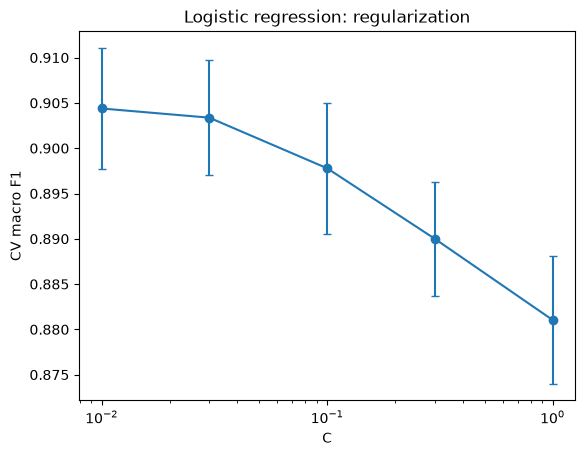

In [44]:
plt.errorbar(C_values, df_logreg.cv_mean, yerr=df_logreg.cv_std, marker='o', capsize=3)
plt.xscale('log')
plt.xlabel('C')
plt.ylabel('CV macro F1')
plt.title('Logistic regression: regularization')
plt.show()

In [45]:
best_C = C_values[df_logreg.cv_mean.idxmax()]
results.append(evaluate(f'logreg C={best_C} balanced',
                        LogisticRegression(C=best_C, max_iter=1000, class_weight='balanced')))
results[-1]

{'model': 'logreg C=0.01 balanced',
 'cv_mean': np.float64(0.9041028407520038),
 'cv_std': np.float64(0.007056648100745443),
 'val_f1': 0.9141274044764996,
 'fit_seconds': 5.028361797332764}

### Decision tree

In [46]:
from sklearn.tree import DecisionTreeClassifier

for depth in [10, 20, 40]:
    for leaf in [1, 5, 20]:
        results.append(evaluate(f'tree depth={depth} leaf={leaf}',
                                DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1)))

pd.DataFrame(results[-9:])

,model,cv_mean,cv_std,val_f1,fit_seconds
0,tree depth=10 leaf=1,0.831253,0.004346,0.838628,3.838441
1,tree depth=10 leaf=5,0.830912,0.004805,0.833536,3.769423
2,tree depth=10 leaf=20,0.830270,0.005888,0.829187,3.436213
3,tree depth=20 leaf=1,0.823091,0.007608,0.835044,6.691477
4,tree depth=20 leaf=5,0.828080,0.005746,0.834680,5.960571
5,tree depth=20 leaf=20,0.833540,0.008238,0.841524,4.600355
6,tree depth=40 leaf=1,0.814802,0.006392,0.831592,8.147383
7,tree depth=40 leaf=5,0.823871,0.005732,0.827280,6.837928
8,tree depth=40 leaf=20,0.833477,0.008138,0.841524,4.728715


### Random forest

In [47]:
from sklearn.ensemble import RandomForestClassifier

for n in [50, 100, 200]:
    for depth in [20, None]:
        results.append(evaluate(f'forest n={n} depth={depth}',
                                RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1)))

pd.DataFrame(results[-6:])

,model,cv_mean,cv_std,val_f1,fit_seconds
0,forest n=50 depth=20,0.797897,0.013816,0.809862,2.263890
1,forest n=50 depth=None,0.869116,0.008380,0.878747,3.115196
2,forest n=100 depth=20,0.805763,0.010375,0.823257,2.567458
3,forest n=100 depth=None,0.876808,0.005466,0.884395,4.124271
4,forest n=200 depth=20,0.810455,0.007903,0.822341,3.051128
5,forest n=200 depth=None,0.879086,0.005596,0.890502,6.273520


### XGBoost

The number of rounds is one of the tuned values, chosen on the folds.

In [48]:
from xgboost import XGBClassifier

for eta in [0.1, 0.3]:
    for rounds in [100, 200]:
        results.append(evaluate(f'xgboost eta={eta} rounds={rounds}',
                                XGBClassifier(learning_rate=eta, n_estimators=rounds, max_depth=6, random_state=1)))

pd.DataFrame(results[-4:])

,model,cv_mean,cv_std,val_f1,fit_seconds
0,xgboost eta=0.1 rounds=100,0.901811,0.005556,0.906284,5.049476
1,xgboost eta=0.1 rounds=200,0.905118,0.005898,0.910461,7.585468
2,xgboost eta=0.3 rounds=100,0.904352,0.004503,0.907532,4.536876
3,xgboost eta=0.3 rounds=200,0.905930,0.004686,0.907436,7.038942


## 19. Comparison

In [49]:
df_results = pd.DataFrame(results).set_index('model').sort_values('val_f1', ascending=False)
df_results.round(4)

,cv_mean,cv_std,val_f1,fit_seconds
model,,,,
logreg C=0.01 balanced,0.9041,0.0071,0.9141,5.0284
xgboost eta=0.1 rounds=200,0.9051,0.0059,0.9105,7.5855
xgboost eta=0.3 rounds=100,0.9044,0.0045,0.9075,4.5369
xgboost eta=0.3 rounds=200,0.9059,0.0047,0.9074,7.0389
xgboost eta=0.1 rounds=100,0.9018,0.0056,0.9063,5.0495
logreg C=0.01,0.9044,0.0067,0.9055,5.2139
logreg C=0.03,0.9034,0.0064,0.9046,5.3504
logreg C=0.1,0.8978,0.0072,0.9037,5.7970
logreg C=0.3,0.8900,0.0063,0.8963,6.0251


Logistic regression with `C=0.01` and balanced class weights is chosen: best on validation and simpler than XGBoost.

## 20. Errors of the chosen model

Per-category scores and the confusion matrix on the validation set.

In [50]:
pipeline = make_pipeline(words_vectorizer(), LogisticRegression(C=0.01, max_iter=1000, class_weight='balanced'))
pipeline.fit(df_train.text, y_train)
y_pred = pipeline.predict(df_val.text)
print(classification_report(y_val, y_pred, labels=categories, digits=3))

               precision    recall  f1-score   support

   JavaScript      0.966     0.951     0.958      3091
         Java      0.930     0.925     0.928      1274
       DevOps      0.967     0.956     0.961      1171
QA Automation      0.964     0.974     0.969      1013
       Python      0.853     0.875     0.864      1071
 Data Science      0.775     0.835     0.804       401

     accuracy                          0.935      8021
    macro avg      0.909     0.919     0.914      8021
 weighted avg      0.936     0.935     0.935      8021



In [51]:
pd.DataFrame(confusion_matrix(y_val, y_pred, labels=categories), index=categories, columns=categories)

,JavaScript,Java,DevOps,QA Automation,Python,Data Science
JavaScript,2939,53,7,12,76,4
Java,45,1179,4,7,22,17
DevOps,13,12,1119,6,8,13
QA Automation,5,3,4,987,10,4
Python,34,13,19,9,937,59
Data Science,6,8,4,3,45,335


In [52]:
errors = df_val[y_pred != y_val].assign(predicted=y_pred[y_pred != y_val])
errors[['position', 'primary_keyword', 'predicted']].sample(10, random_state=1)

,position,primary_keyword,predicted
7393,Senior React Engineer for live streaming company,JavaScript,Java
6023,Scala Developer,Java,Data Science
3126,Java Lead,Java,JavaScript
5210,Python Data engineer,Python,Data Science
1124,DevOps Developer,Python,DevOps
4398,Middle JavaScript Developer,JavaScript,Java
517,AWS Solution Architect for Avalanche Labs,DevOps,Data Science
5669,QA Engineer,JavaScript,QA Automation
3658,Junior Vue.js Developer,JavaScript,Python
3481,Junior Java Configurator,Java,Data Science


Words with the largest coefficient for each category.

In [53]:
words = pipeline[0].get_feature_names_out()
model = pipeline[-1]
pd.DataFrame({c: words[np.argsort(model.coef_[i])[::-1][:10]] for i, c in enumerate(model.classes_)})

,Data Science,DevOps,Java,JavaScript,Python,QA Automation
0,data,devops,java,react,python,automation
1,scientist,terraform,spring,javascript,django,qa
2,models,infrastructure,developer,developer,developer,test
3,bi,kubernetes,boot,typescript,flask,testing
4,etl,linux,kotlin,angular,backend,tests
5,machine,scripting,hibernate,front,celery,selenium
6,spark,engineer,backend,frontend,postgresql,aqa
7,analyst,administration,core,node.js,fastapi,automated
8,scala,monitoring,unit,css,back,manual
9,sql,bash,kafka,react.js,efficient,cases


## 21. Final model

Trained on training plus validation and evaluated once on the test set.

In [54]:
df_full_train = pd.concat([df_train, df_val]).reset_index(drop=True)
y_full_train = df_full_train.primary_keyword.values
y_test = df_test.primary_keyword.values

pipeline = make_pipeline(words_vectorizer(), LogisticRegression(C=0.01, max_iter=1000, class_weight='balanced'))
pipeline.fit(df_full_train.text, y_full_train)
y_pred = pipeline.predict(df_test.text)

print('test macro F1:', round(f1_score(y_test, y_pred, average='macro'), 4))
print('test accuracy:', round(accuracy_score(y_test, y_pred), 4))

test macro F1: 0.911
test accuracy: 0.9339


In [55]:
print(classification_report(y_test, y_pred, labels=categories, digits=3))

               precision    recall  f1-score   support

   JavaScript      0.975     0.946     0.961      3059
         Java      0.906     0.926     0.916      1162
       DevOps      0.966     0.950     0.958      1211
QA Automation      0.961     0.966     0.963       928
       Python      0.840     0.865     0.852       886
 Data Science      0.756     0.886     0.816       332

     accuracy                          0.934      7578
    macro avg      0.901     0.923     0.911      7578
 weighted avg      0.936     0.934     0.935      7578

